# DETECCIÓN DE LAS LÍNEAS DE LOS CARRILES CON TRANSFORMADA DE HOUGH

Juan David Hurtado Molano

Laura Sofía Salamanca Barrera

Segunda entrega. El objetivo de este notebook es uno solo: obtener las líneas de los carriles (corcheras y guías de fondo) con `cv2.HoughLinesP`. Para que el resultado sea un carril = una línea limpia, y no una nube de segmentos sueltos, se apoya en tres limpiezas:

1.  **ROI de piscina**: la máscara de agua de `detector_color.py` (primera entrega) recorta la región donde buscar bordes, en vez de barrer la imagen completa. Evita que el público, el deck o los gráficos del marcador aporten líneas.
2.  **Filtro por ángulo**: de las rectas que salen de Hough, solo se conservan las cercanas a la horizontal — así son los carriles cuando la cámara mira de costado — y se descartan las diagonales que sí se cuelan desde dentro de la piscina.
3.  **Fusión de segmentos**: Hough devuelve cada carril partido en decenas de segmentos cortos. Los segmentos casi colineales se agrupan y se reemplazan por una sola línea de punta a punta.

Se trabaja sobre las cuatro vistas de `data/images`: **ISL** (superior lateral, corcheras casi horizontales vistas desde arriba), **IL** (lateral fuera de la piscina, cámara a ras de agua), **ILP** (lateral dentro del agua, cámara sumergida) e **IS** (superior, cámara en planta).

**IS es distinta a las otras tres**: ahí la cámara mira derecho hacia abajo, así que los carriles no son casi horizontales — son básicamente verticales en el cuadro, un mapa en planta. El filtro por ángulo (pensado para "casi horizontal") y la fusión (que asume pendientes chicas) no aplican ahí. Para IS el pipeline se corta después de Hough: se muestran los segmentos tal cual salen, sin filtrar por ángulo ni fusionar.


In [40]:
from __future__ import annotations

import sys
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, Dropdown, IntSlider

ROOT = Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import detector_color as dc  # máscara de agua de la primera entrega

IMAGES_DIR = ROOT / "data" / "images"
VISTAS = ("ISL", "IL", "ILP", "IS")


## 1. Imágenes de trabajo

Todas las imágenes de `data/images/ISL`, `data/images/IL`, `data/images/ILP` y `data/images/IS`, ya clasificadas por plano en la primera entrega.


In [41]:
rutas_por_vista = {
    vista: sorted((IMAGES_DIR / vista).glob("*.jpg"))
    for vista in VISTAS
}
for vista, rutas in rutas_por_vista.items():
    print(f"{vista}: {len(rutas)} imágenes")


ISL: 20 imágenes
IL: 20 imágenes
ILP: 20 imágenes
IS: 20 imágenes


## 2. Delimitar la piscina antes de buscar líneas

La máscara de agua de `detector_color.py` (blanco = agua) sirve de punto de partida, pero no alcanza tal cual como región de búsqueda: dentro de la piscina quedan huecos negros donde la máscara descarta nadadores, corcheras y guías — justamente lo que queremos conservar para la Hough. Y fuera de la piscina puede sobrar algún parche azul de un gráfico o del marcador que no forma parte del agua real.

Limpieza en dos pasos sobre la máscara de color:

*   **Cierre morfológico** (`MORPH_CLOSE` con un kernel elíptico grande): tapa los huecos de corcheras, cuerdas y nadadores sin crecer el contorno exterior.
*   **Componente conexa más grande**: de lo que quede, solo se conserva el blob más grande. Un gráfico o reflejo azul suelto por fuera de la piscina no queda pegado a ese blob y se descarta aunque haya pasado el filtro de color.

El resultado es la región (ROI) donde tiene sentido buscar los carriles: la piscina completa, sin sus huecos internos.

El tamaño del kernel de cierre no es el mismo en las cuatro vistas. En IL e ILP las corcheras cruzan todo el ancho del cuadro y son más gruesas que en ISL o IS, así que un kernel chico no las tapa: el agua queda cortada en franjas y la componente conexa más grande pierde los carriles más lejanos. Con un kernel más grande para esas dos vistas, las franjas se sueldan en un solo bloque.


In [42]:
KERNEL_ROI_POR_VISTA = {"ISL": 25, "IL": 45, "ILP": 55, "IS": 25}


def roi_piscina(mascara_agua: np.ndarray, kernel: int = 25) -> np.ndarray:
    """Cierra los huecos internos de la máscara de agua y se queda con el blob más grande."""
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kernel, kernel))
    cerrado = cv2.morphologyEx(mascara_agua, cv2.MORPH_CLOSE, k)
    n, etiquetas, stats, _ = cv2.connectedComponentsWithStats(cerrado, connectivity=8)
    if n <= 1:
        return cerrado
    mayor = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    return ((etiquetas == mayor) * 255).astype(np.uint8)


def mascara_agua(imagen_bgr: np.ndarray, vista: str) -> np.ndarray:
    """Cada vista tiene su propia segmentación de color, definida en detector_color.py."""
    if vista == "IS":
        return dc.segmentar_is(imagen_bgr)
    if vista == "ILP":
        return dc.segmentar_ilp(imagen_bgr)
    return dc.segmentar_agua(imagen_bgr, vista)  # ISL e IL


## 3. Bordes, Hough, filtro por ángulo y fusión de segmentos

`cv2.Canny` ya no corre sobre la imagen en gris: corre directo sobre la **máscara de agua** (blanco = agua, negro = corchera/nadador/fondo). La razón es la misma pregunta que nos hicimos antes: ¿por qué la máscara no tiene el ruido de los brillos del agua pero el Canny sobre gris sí? Porque la máscara se arma con el tono (H), que apenas varía con un reflejo (std≈3 en agua pura), mientras que el gris mide brillo, que varía muchísimo (std≈37-50) con cada ola o reflejo. Si Canny corre sobre la máscara en vez de sobre el gris, hereda esa misma inmunidad: dentro de una zona de agua la máscara es un bloque sólido de 255, sin textura que generar como borde falso. Los únicos bordes que puede encontrar son las fronteras agua / no-agua — exactamente las corcheras y guías que buscamos. El filtro bilateral que usábamos antes ya no hace falta: no hay textura de brillo que suavizar en una máscara binaria.

El mapa de bordes se recorta con el ROI de la piscina: así `cv2.HoughLinesP` no pierde tiempo ni genera falsos positivos sobre el público, el deck o un marcador.

`HoughLinesP` (la variante probabilística) devuelve directamente los segmentos, no rectas infinitas, lo que facilita dibujarlos y filtrarlos. Pero recortar por ROI no alcanza: un recuadro gráfico del marcador queda *dentro* de la piscina (mismo blob de agua) y su contorno en la máscara también genera rectas. Esas rectas espurias salen en diagonal, mientras que un carril real —corchera o guía de fondo— es casi horizontal en ISL, IL e ILP. Por eso, el penúltimo paso descarta toda recta cuyo ángulo respecto a la horizontal supere un umbral.

Incluso después de ese filtro, cada carril real no siempre queda como una sola línea: un nadador o una sombra puede cortar el contorno de la máscara en un par de segmentos. El último paso los **fusiona**: dos segmentos casi horizontales se consideran el mismo carril si, al proyectarlos hacia el punto medio entre ambos, caen a una altura parecida. Los que terminan en el mismo grupo se reemplazan por una sola línea, de su extremo más a la izquierda a su extremo más a la derecha.

Esa proyección se hace a un punto *local* (el punto medio entre cada par de segmentos), no a un punto fijo de la imagen. En ISL la perspectiva es fuerte — las corcheras no son paralelas, convergen hacia la derecha — así que comparar dos segmentos lejanos en un único punto de referencia fijo los hace coincidir por casualidad aunque sean carriles distintos. Comparándolos en un punto entre ambos, dos carriles realmente distintos casi nunca coinciden salvo que ya estén muy cerca.

**IS es la excepción**: ahí la cámara mira derecho hacia abajo y los carriles corren verticales en el cuadro, no horizontales. El filtro de ángulo y la fusión asumen pendientes chicas (están pensados para líneas casi horizontales), así que para IS el pipeline se detiene justo después de Hough — se muestran los segmentos tal cual, sin filtrar ni fusionar.


In [43]:
def filtrar_por_angulo(lineas: np.ndarray, angulo_max: float) -> np.ndarray:
    """Conserva solo los segmentos cercanos a la horizontal: así se ven los carriles en ISL e IL."""
    if len(lineas) == 0:
        return lineas
    angulos = np.degrees(np.arctan2(lineas[:, 3] - lineas[:, 1], lineas[:, 2] - lineas[:, 0]))
    distancia_horizontal = np.abs(((angulos + 90) % 180) - 90)
    return lineas[distancia_horizontal <= angulo_max]


def _normalizar_extremos(lineas: np.ndarray) -> np.ndarray:
    """Garantiza x1 <= x2 en cada segmento, para que el ángulo no dependa de qué extremo dio Hough primero."""
    lineas = lineas.copy()
    invertir = lineas[:, 0] > lineas[:, 2]
    lineas[invertir] = lineas[invertir][:, [2, 3, 0, 1]]
    return lineas


class _UnionFind:
    """Agrupa índices de segmentos que terminan siendo el mismo carril."""

    def __init__(self, n: int):
        self.padre = list(range(n))

    def encontrar(self, x: int) -> int:
        while self.padre[x] != x:
            self.padre[x] = self.padre[self.padre[x]]
            x = self.padre[x]
        return x

    def unir(self, a: int, b: int) -> None:
        ra, rb = self.encontrar(a), self.encontrar(b)
        if ra != rb:
            self.padre[ra] = rb


def fusionar_lineas(lineas: np.ndarray, offset_max: float, angulo_max_grupo: float) -> np.ndarray:
    """Une segmentos casi colineales en una sola línea por carril (de su extremo izquierdo al derecho).

    Dos segmentos se consideran el mismo carril si, evaluados en el punto medio entre ambos
    (no en un punto fijo de la imagen), caen a una altura parecida y su ángulo es similar.
    Comparar en un punto local evita que corcheras distintas se fusionen por casualidad en
    vistas con mucha perspectiva (ISL), donde las líneas no son paralelas.
    """
    if len(lineas) == 0:
        return lineas
    lineas = _normalizar_extremos(lineas)
    n = len(lineas)
    angulos = np.degrees(np.arctan2(lineas[:, 3] - lineas[:, 1], lineas[:, 2] - lineas[:, 0]))
    pendientes = np.tan(np.radians(angulos))
    x_medio = (lineas[:, 0] + lineas[:, 2]) / 2

    grupos = _UnionFind(n)
    for i in range(n):
        for j in range(i + 1, n):
            if abs(angulos[i] - angulos[j]) > angulo_max_grupo:
                continue
            x_test = (x_medio[i] + x_medio[j]) / 2
            y_i = lineas[i, 1] + pendientes[i] * (x_test - lineas[i, 0])
            y_j = lineas[j, 1] + pendientes[j] * (x_test - lineas[j, 0])
            if abs(y_i - y_j) <= offset_max:
                grupos.unir(i, j)

    por_grupo: dict[int, list[int]] = {}
    for i in range(n):
        por_grupo.setdefault(grupos.encontrar(i), []).append(i)

    fusionadas = []
    for indices in por_grupo.values():
        segmentos = lineas[indices]
        puntos = np.vstack([segmentos[:, :2], segmentos[:, 2:]])
        izquierda = puntos[np.argmin(puntos[:, 0])]
        derecha = puntos[np.argmax(puntos[:, 0])]
        fusionadas.append([int(izquierda[0]), int(izquierda[1]), int(derecha[0]), int(derecha[1])])
    return np.array(fusionadas, dtype=int)


def detectar_lineas(
    imagen_bgr: np.ndarray,
    vista: str,
    kernel_roi: int | None = None,
    canny_bajo: int = 40,
    canny_alto: int = 120,
    hough_umbral: int = 60,
    longitud_min: int = 80,
    hueco_max: int = 20,
    angulo_max: int = 10,
    fusion_offset: int = 10,
    fusion_angulo: int = 3,
) -> dict:
    """Pipeline completo: máscara de agua -> ROI de piscina -> Canny sobre la máscara -> Hough -> filtro por ángulo -> fusión."""
    if kernel_roi is None:
        kernel_roi = KERNEL_ROI_POR_VISTA.get(vista, 25)
    agua = mascara_agua(imagen_bgr, vista)
    roi = roi_piscina(agua, kernel_roi)

    bordes = cv2.Canny(agua, canny_bajo, canny_alto)
    bordes_roi = cv2.bitwise_and(bordes, bordes, mask=roi)

    lineas = cv2.HoughLinesP(
        bordes_roi,
        rho=1,
        theta=np.pi / 180,
        threshold=hough_umbral,
        minLineLength=longitud_min,
        maxLineGap=hueco_max,
    )
    lineas = lineas.reshape(-1, 4) if lineas is not None else np.empty((0, 4), dtype=int)
    if vista == "IS":
        # Vista en planta: los carriles no son casi horizontales, así que el filtro de
        # ángulo y la fusión (pensados para pendientes chicas) no aplican acá.
        carriles = lineas
    else:
        carriles = filtrar_por_angulo(lineas, angulo_max)
        carriles = fusionar_lineas(carriles, fusion_offset, fusion_angulo)

    resultado = imagen_bgr.copy()
    for x1, y1, x2, y2 in carriles:
        cv2.line(resultado, (int(x1), int(y1)), (int(x2), int(y2)), (0, 0, 255), 3)

    return {
        "agua": agua,
        "roi": roi,
        "bordes": bordes_roi,
        "lineas": carriles,
        "resultado": resultado,
    }


## 4. Visualización interactiva (tiempo real)

Sliders sobre el kernel del ROI, los dos umbrales de Canny, los tres parámetros de `HoughLinesP`, el ángulo máximo del filtro y los dos parámetros de la fusión final. Cada cambio recalcula el pipeline completo sobre la imagen elegida y redibuja: máscara de agua, ROI de piscina, bordes recortados y los carriles ya fusionados en una línea por carril.


In [44]:
rutas_todas = {f"{vista}/{r.name}": r for vista in VISTAS for r in rutas_por_vista[vista]}


def _mostrar(imagen_bgr, agua, roi, bordes, resultado, lineas, titulo):
    rgb = lambda im: cv2.cvtColor(im, cv2.COLOR_BGR2RGB)
    solo_lineas = np.zeros_like(imagen_bgr)
    for x1, y1, x2, y2 in lineas:
        cv2.line(solo_lineas, (int(x1), int(y1)), (int(x2), int(y2)), (255, 255, 255), 3)

    fig, ax = plt.subplots(1, 6, figsize=(32, 6))
    ax[0].imshow(rgb(imagen_bgr)); ax[0].set_title("Original")
    ax[1].imshow(agua, cmap="gray"); ax[1].set_title("Máscara de agua")
    ax[2].imshow(roi, cmap="gray"); ax[2].set_title("ROI piscina (bordes buscan solo aquí)")
    ax[3].imshow(bordes, cmap="gray"); ax[3].set_title("Canny recortado al ROI (entrada de Hough)")
    ax[4].imshow(rgb(resultado)); ax[4].set_title("Carriles (filtrados por ángulo)")
    ax[5].imshow(rgb(solo_lineas)); ax[5].set_title("Solo los carriles (sin la imagen)")
    for a in ax:
        a.axis("off")
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()
    print(f"bordes activos: {int((bordes > 0).sum())} px | líneas detectadas: {len(lineas)}")


def explorar(
    imagen=Dropdown(options=list(rutas_todas), value=next(iter(rutas_todas))),
    kernel_roi=IntSlider(min=3, max=61, step=2, value=25),
    canny_bajo=IntSlider(min=0, max=255, step=5, value=40),
    canny_alto=IntSlider(min=0, max=255, step=5, value=120),
    hough_umbral=IntSlider(min=5, max=200, step=5, value=60),
    longitud_min=IntSlider(min=5, max=300, step=5, value=80),
    hueco_max=IntSlider(min=1, max=100, step=1, value=20),
    angulo_max=IntSlider(min=1, max=45, step=1, value=10),
    fusion_offset=IntSlider(min=1, max=50, step=1, value=10),
    fusion_angulo=IntSlider(min=1, max=15, step=1, value=3),
):
    ruta = rutas_todas[imagen]
    vista = ruta.parent.name
    frame = cv2.imread(str(ruta))
    salida = detectar_lineas(
        frame, vista,
        kernel_roi=kernel_roi,
        canny_bajo=canny_bajo,
        canny_alto=canny_alto,
        hough_umbral=hough_umbral,
        longitud_min=longitud_min,
        hueco_max=hueco_max,
        angulo_max=angulo_max,
        fusion_offset=fusion_offset,
        fusion_angulo=fusion_angulo,
    )
    _mostrar(frame, salida["agua"], salida["roi"], salida["bordes"], salida["resultado"], salida["lineas"], f"{imagen}  ({vista})")


interact(explorar)


interactive(children=(Dropdown(description='imagen', options=('ISL/ISL_00204.jpg', 'ISL/ISL_00408.jpg', 'ISL/I…

<function __main__.explorar(imagen=Dropdown(description='imagen', options=('ISL/ISL_00204.jpg', 'ISL/ISL_00408.jpg', 'ISL/ISL_00612.jpg', 'ISL/ISL_00816.jpg', 'ISL/ISL_01020.jpg', 'ISL/ISL_01224.jpg', 'ISL/ISL_01428.jpg', 'ISL/ISL_01632.jpg', 'ISL/ISL_01836.jpg', 'ISL/ISL_02040.jpg', 'ISL/ISL_02244.jpg', 'ISL/ISL_02448.jpg', 'ISL/ISL_02652.jpg', 'ISL/ISL_02856.jpg', 'ISL/ISL_03060.jpg', 'ISL/ISL_03264.jpg', 'ISL/ISL_03468.jpg', 'ISL/ISL_03672.jpg', 'ISL/ISL_03876.jpg', 'ISL/ISL_04080.jpg', 'IL/IL_00099.jpg', 'IL/IL_00198.jpg', 'IL/IL_00297.jpg', 'IL/IL_00396.jpg', 'IL/IL_00495.jpg', 'IL/IL_00594.jpg', 'IL/IL_00693.jpg', 'IL/IL_00792.jpg', 'IL/IL_00891.jpg', 'IL/IL_00990.jpg', 'IL/IL_01089.jpg', 'IL/IL_01188.jpg', 'IL/IL_01287.jpg', 'IL/IL_01386.jpg', 'IL/IL_01485.jpg', 'IL/IL_01584.jpg', 'IL/IL_01683.jpg', 'IL/IL_01782.jpg', 'IL/IL_01881.jpg', 'IL/IL_01980.jpg', 'ILP/ILP_00185.jpg', 'ILP/ILP_00370.jpg', 'ILP/ILP_00555.jpg', 'ILP/ILP_00740.jpg', 'ILP/ILP_00925.jpg', 'ILP/ILP_01110.jpg',

## 5. Ejemplos fijos (las 4 vistas)

Una imagen de cada vista con los parámetros por defecto, para tener una referencia que no dependa de mover los sliders (útil al exportar el notebook a PDF/HTML, donde el widget interactivo no se ve).


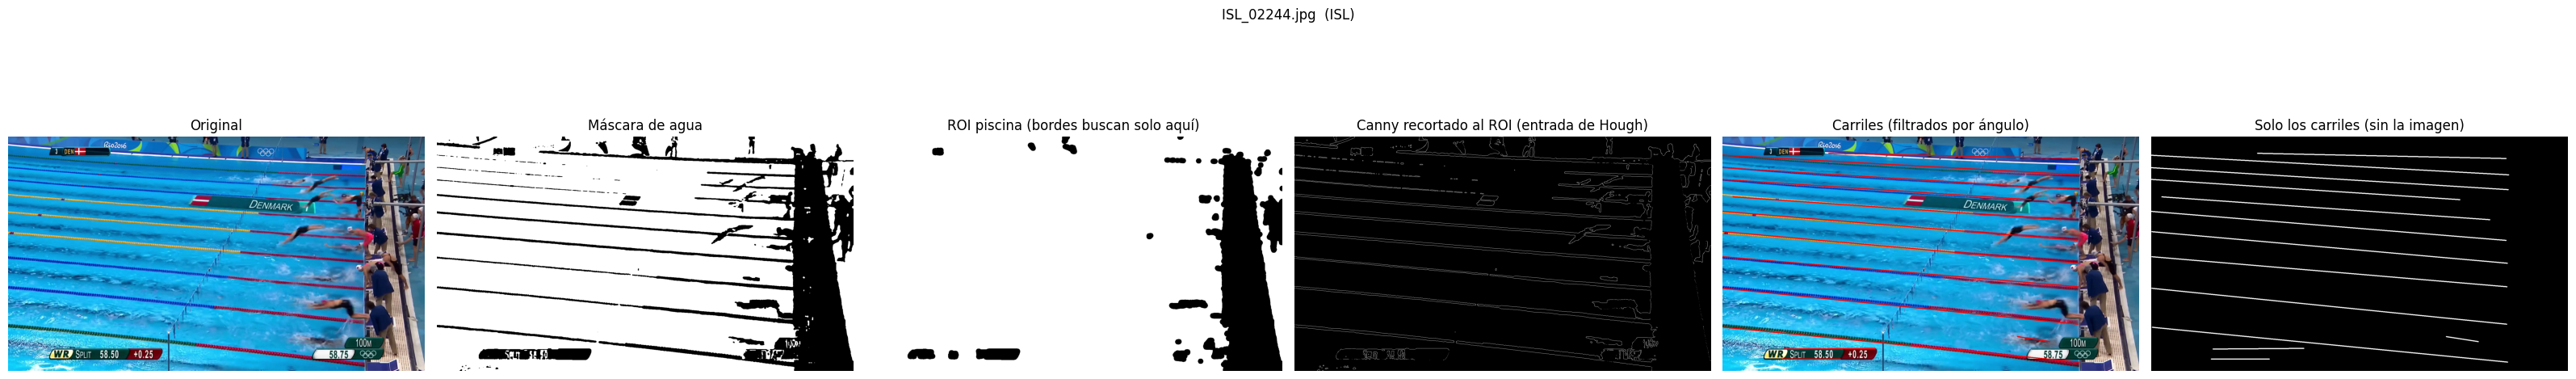

bordes activos: 40608 px | líneas detectadas: 13


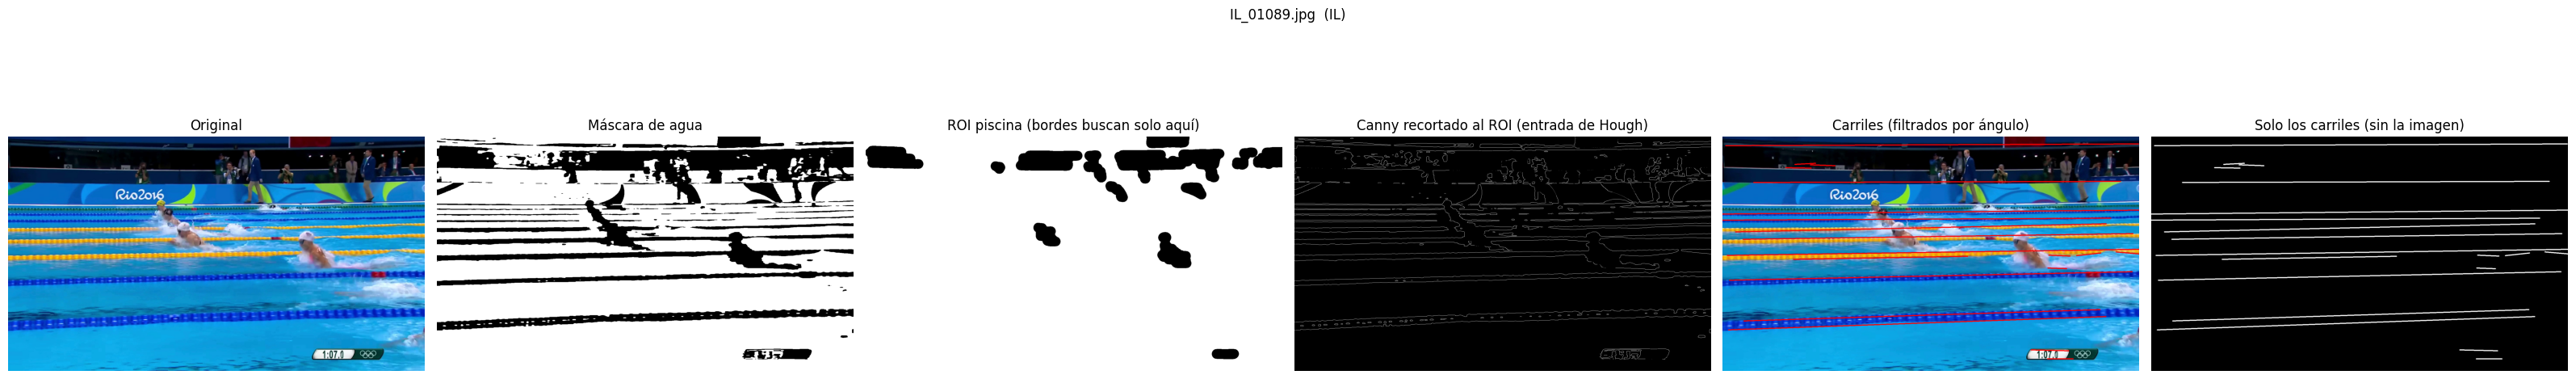

bordes activos: 51287 px | líneas detectadas: 20


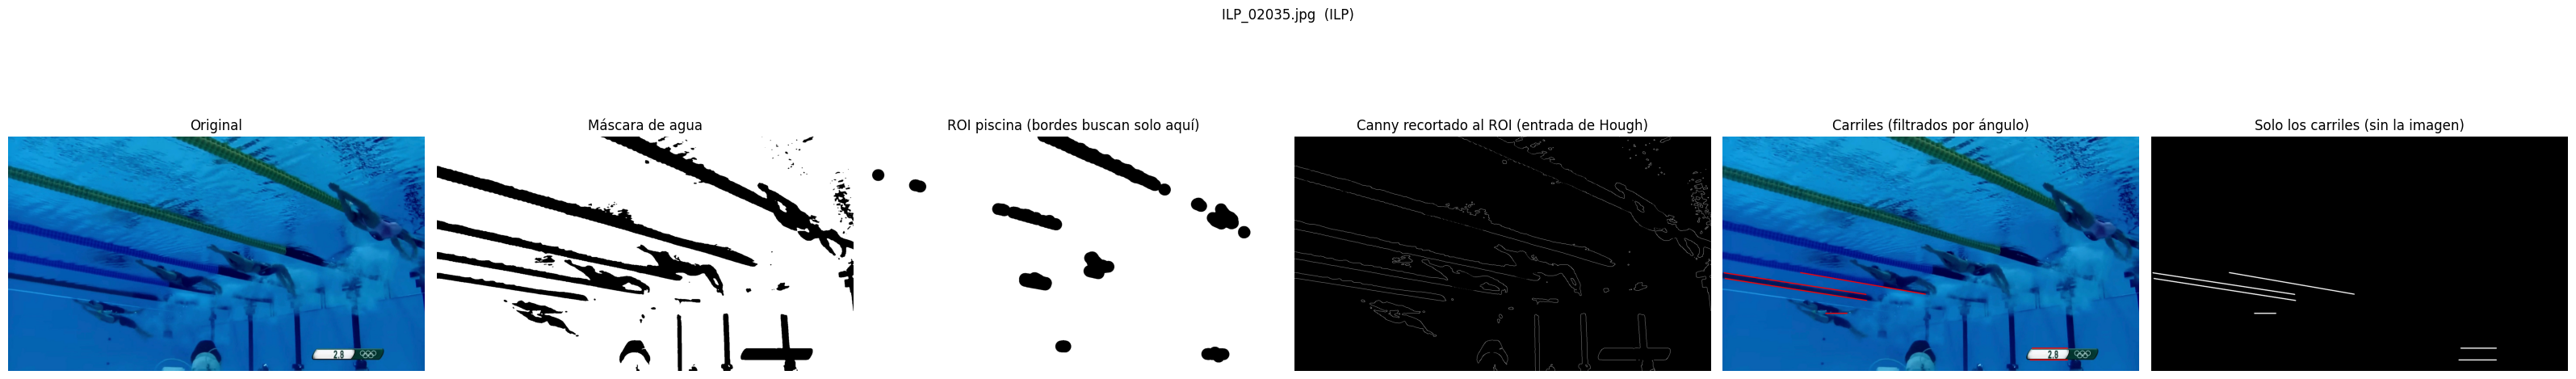

bordes activos: 22130 px | líneas detectadas: 6


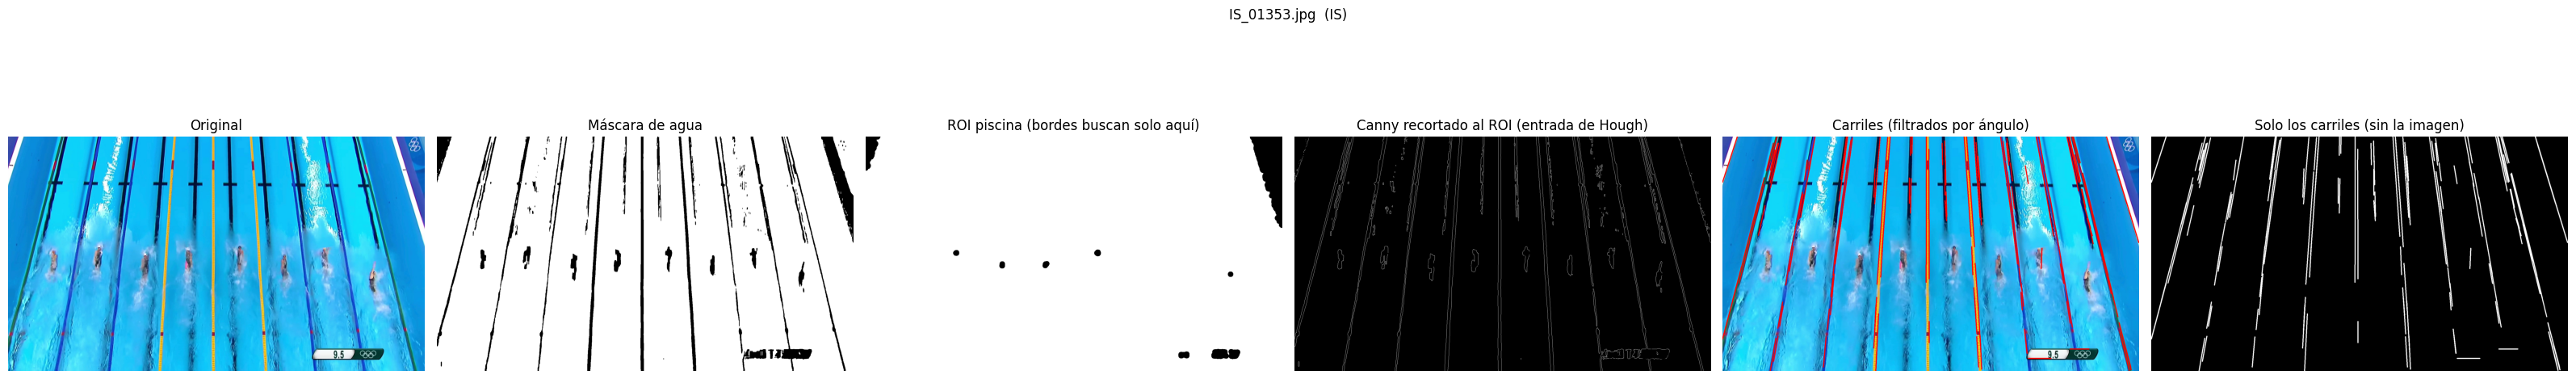

bordes activos: 34454 px | líneas detectadas: 147


In [6]:
for vista in VISTAS:
    ruta = rutas_por_vista[vista][len(rutas_por_vista[vista]) // 2]
    frame = cv2.imread(str(ruta))
    salida = detectar_lineas(frame, vista)
    _mostrar(frame, salida["agua"], salida["roi"], salida["bordes"], salida["resultado"], salida["lineas"], f"{ruta.name}  ({vista})")


## 6. Observaciones

*   **Antes de fusionar**: aun con ROI, filtro de ángulo y el kernel de cierre calibrado por vista, cada carril real salía como docenas de segmentos cortos y separados. Visualmente se veía "punteado", no como una línea.
*   **Primer intento de fusión (punto de referencia fijo)**: agrupar los segmentos extrapolando todos a un mismo punto x de la imagen funcionó bien en IL, pero en ISL fusionó corcheras distintas entre sí por la perspectiva fuerte. Se resolvió comparando cada par de segmentos en el punto medio entre ambos, no en un punto fijo.
*   **Filtro bilateral antes de Canny**: cambiar el desenfoque Gaussian por un filtro bilateral (suaviza el agua, no los bordes marcados) bajó bastante el ruido sin perder corcheras reales.
*   **Canny directo sobre la máscara de agua (el cambio más grande)**: la pregunta que lo disparó fue por qué la máscara de color no tiene ruido de brillos pero el Canny sobre gris sí. La respuesta: sobre agua pura, el tono (H, lo que usa la máscara) tiene desviación estándar ≈3, mientras que el gris (lo que usaba Canny) tiene ≈37-50 — un reflejo cambia mucho el brillo pero casi nada el tono. Corriendo Canny directo sobre la máscara binaria se elimina casi toda la textura de oleaje. El filtro bilateral ya no hace falta y se sacó del pipeline.
*   **Las 4 vistas**: ISL, IL e ILP comparten el mismo pipeline (cada una con su máscara de color y su kernel de cierre, definidos en `detector_color.py` y `KERNEL_ROI_POR_VISTA`). **IS no**: ahí los carriles son verticales, no horizontales, así que el filtro de ángulo y la fusión no aplican — para IS se muestran los segmentos de Hough tal cual salen, sin ese post-procesamiento. Aun así, en IS el resultado ya sale bastante limpio sin fusionar: al mirar derecho hacia abajo no hay perspectiva fuerte deformando las corcheras, así que Hough las recupera como líneas largas directamente.
*   Quedan algunos cruces menores donde un segmento de ruido cae justo entre dos carriles reales y los conecta, y el contorno de un recuadro gráfico dentro de la piscina (como el del marcador en ISL) sigue generando alguna línea corta.
